# 00 — MIMIC-IV-ECG Sample Waveforms (`[11, 13, 19, 92, 42]`)

Quick visual inspection of five individual 12-lead MIMIC-IV-ECG recordings (`500 Hz`, `10 s`, `5,000` samples per lead) at dataset indices **`11`, `13`, `19`, `92`, and `42`**:

1. **Metadata & Machine Report Summary** for the five selected studies.
2. **Full 12-Lead Waveform Plots** (`6 × 2` grid, all `10 s`) for each sample.
3. **Cross-Sample Lineplots** comparing Lead II and Lead V2 (`0–5 s` zoom) side by side.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import wfdb

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 120, "savefig.bbox": "tight"})

_cwd = Path.cwd().resolve()
for _candidate in [_cwd, _cwd.parent, _cwd.parent.parent]:
    if (_candidate / "mimic_iv_ecg" / "data" / "record_list.csv").exists():
        REPO_ROOT = _candidate
        break
else:
    raise FileNotFoundError(f"Could not locate mimic_iv_ecg/data/record_list.csv from {_cwd}")

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

DATA_DIR = REPO_ROOT / "mimic_iv_ecg" / "data"
LEADS = ["I", "II", "III", "aVR", "aVL", "aVF", "V1", "V2", "V3", "V4", "V5", "V6"]
SAMPLE_INDICES = [11, 13, 19, 92, 42]

rl = pd.read_csv(DATA_DIR / "record_list.csv").iloc[SAMPLE_INDICES].copy()
rl.insert(0, "sample_idx", SAMPLE_INDICES)

mm = pd.read_csv(DATA_DIR / "machine_measurements.csv", low_memory=False)
mm_sub = mm[mm["study_id"].isin(rl["study_id"])].set_index("study_id")
rep_cols = [f"report_{i}" for i in range(18) if f"report_{i}" in mm_sub.columns]

meta_rows = []
signals = {}
for _, row in rl.iterrows():
    idx = int(row["sample_idx"])
    sid = int(row["study_id"])
    sig, _ = wfdb.rdsamp(str(DATA_DIR / row["path"]))
    signals[idx] = np.nan_to_num(sig).astype(np.float32)  # (5000, 12)
    mrow = mm_sub.loc[sid]
    reports = " | ".join(str(mrow[c]).strip() for c in rep_cols if pd.notna(mrow[c]) and str(mrow[c]).strip())
    rr = mrow["rr_interval"]
    hr = round(60000.0 / rr, 1) if (pd.notna(rr) and 200 <= rr <= 3000) else np.nan
    meta_rows.append({
        "sample_idx": idx,
        "subject_id": int(row["subject_id"]),
        "study_id": sid,
        "ecg_time": row["ecg_time"],
        "hr_bpm": hr,
        "filtering": mrow["filtering"],
        "report": reports,
    })

meta_df = pd.DataFrame(meta_rows).set_index("sample_idx")
display(meta_df)

,subject_id,study_id,ecg_time,hr_bpm,filtering,report
sample_idx,,,,,,
11,10000635,43522917,2137-02-07 13:58:00,57.0,60 Hz notch Baseline filter,Sinus bradycardia | Left ventricular hypertrop...
13,10000635,42947358,2139-01-22 14:09:00,58.0,60 Hz notch Baseline filter,Sinus bradycardia with interpolated PVC(s) | E...
19,10000826,40695233,2146-12-12 08:42:00,96.0,60 Hz notch Baseline filter,Sinus rhythm | Normal ECG
92,10001843,44881309,2131-11-09 13:20:00,54.0,60 Hz notch Baseline filter,Sinus bradycardia with PVC(s) | Normal ECG exc...
42,10000980,42742896,2189-06-27 14:36:00,68.0,60 Hz notch Baseline filter,Sinus rhythm. | Leftward axis | rSr'(V1) - pro...


## 1. Full 12-Lead Waveform Plots (`10 s @ 500 Hz`)

Each figure below displays all 12 leads (`I..V6`) for one sample (`11`, `13`, `19`, `92`, `42`) across the full 10-second recording.

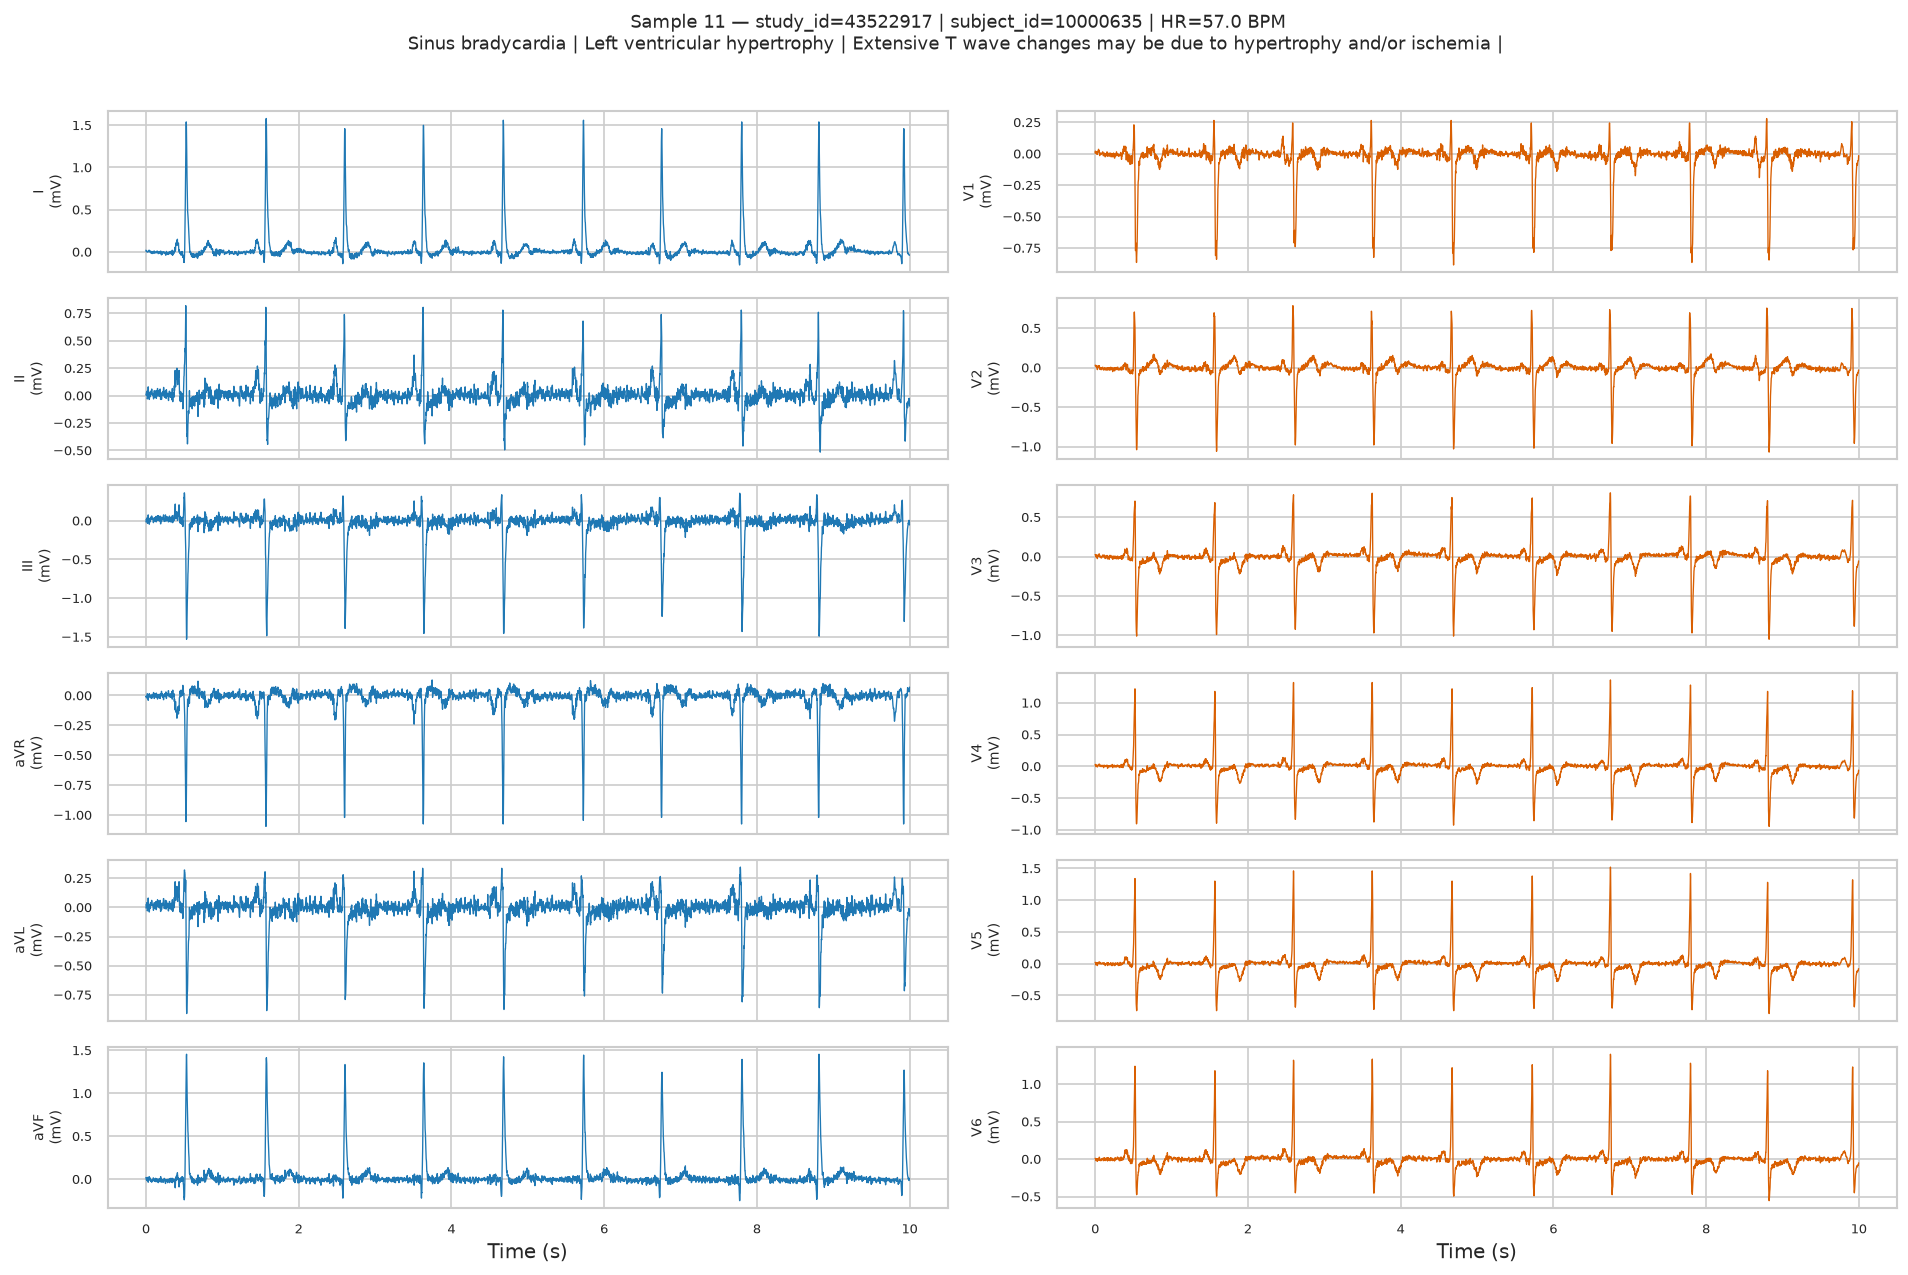

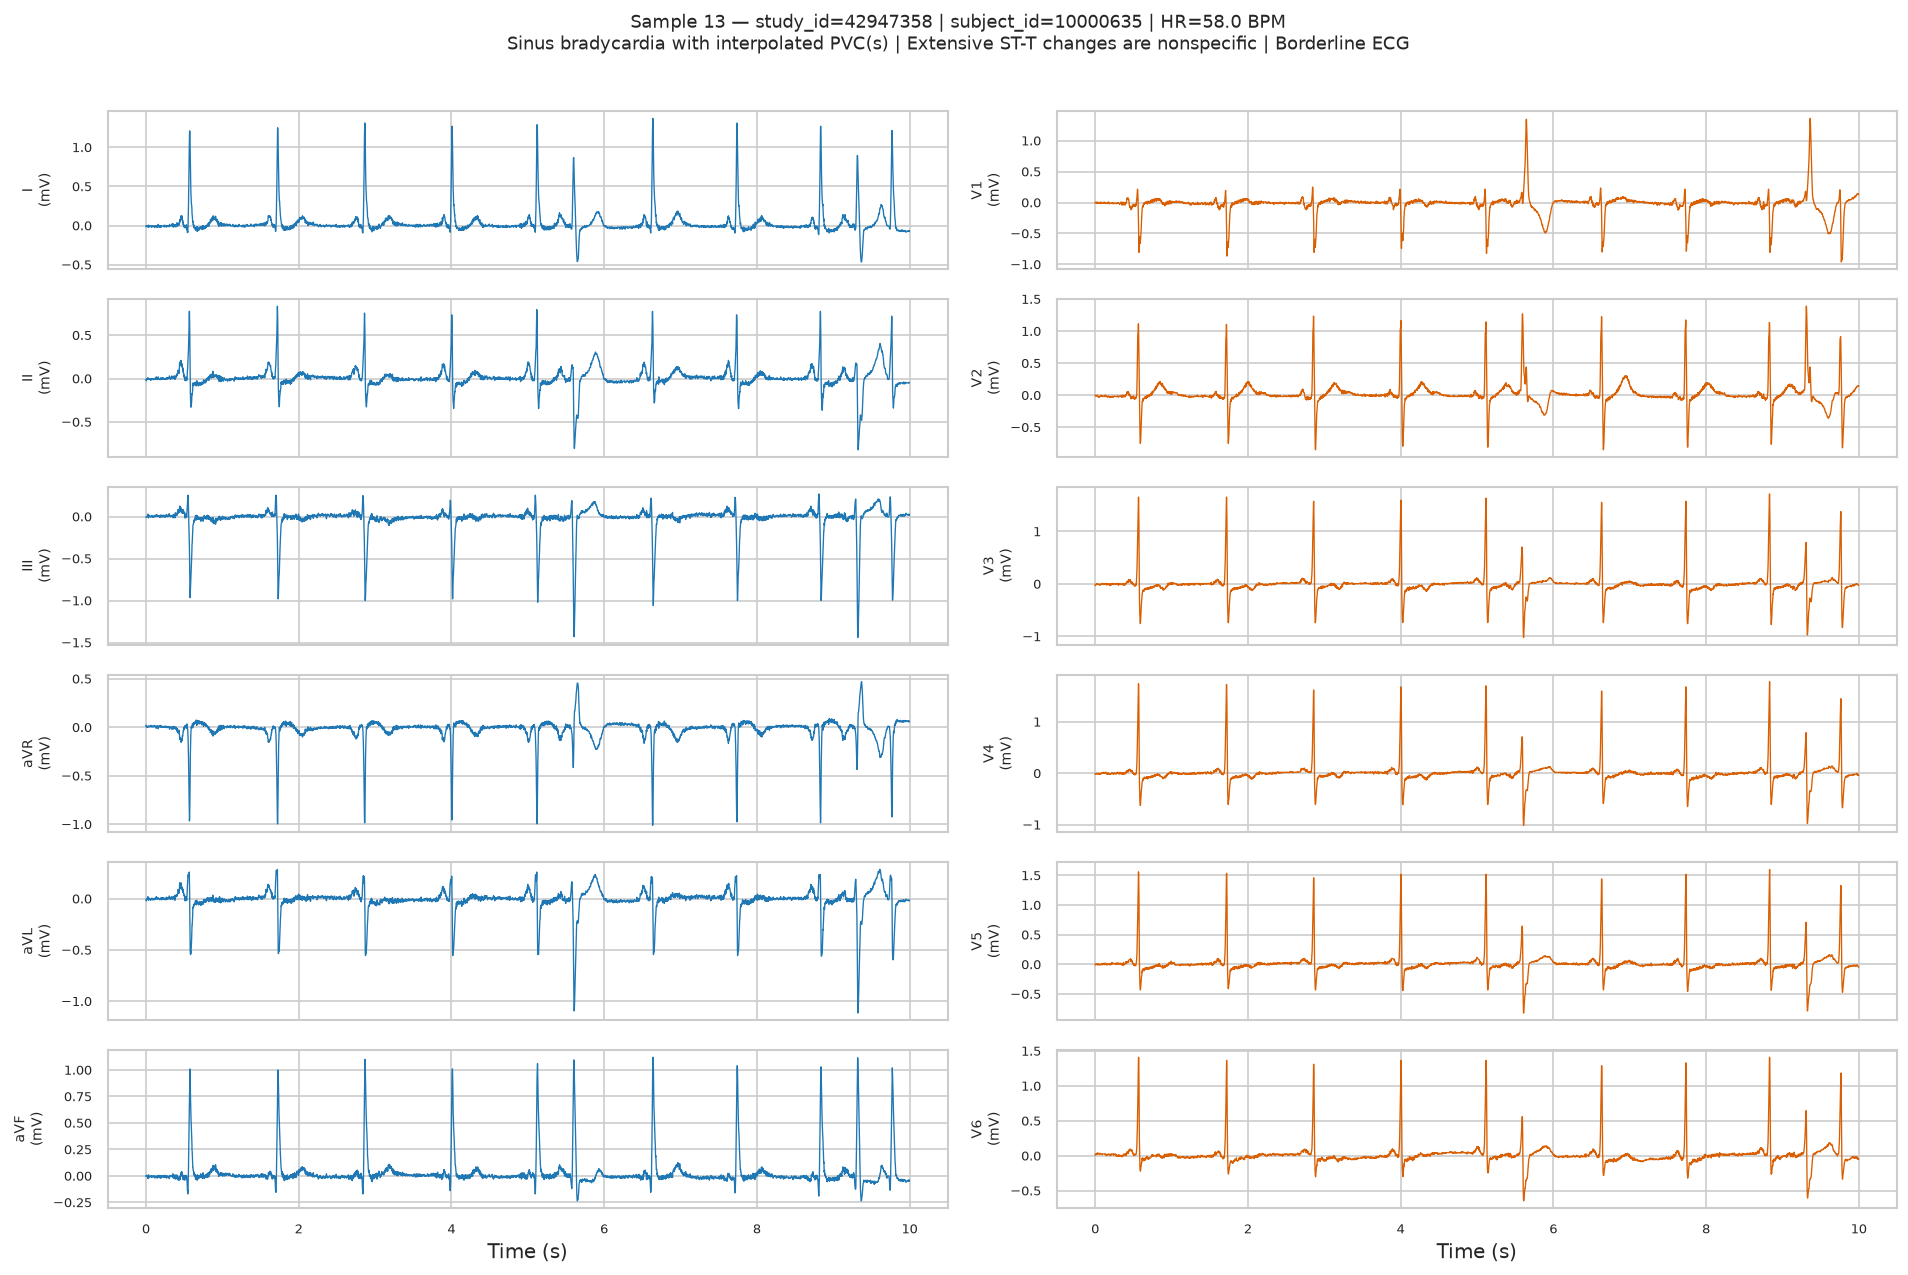

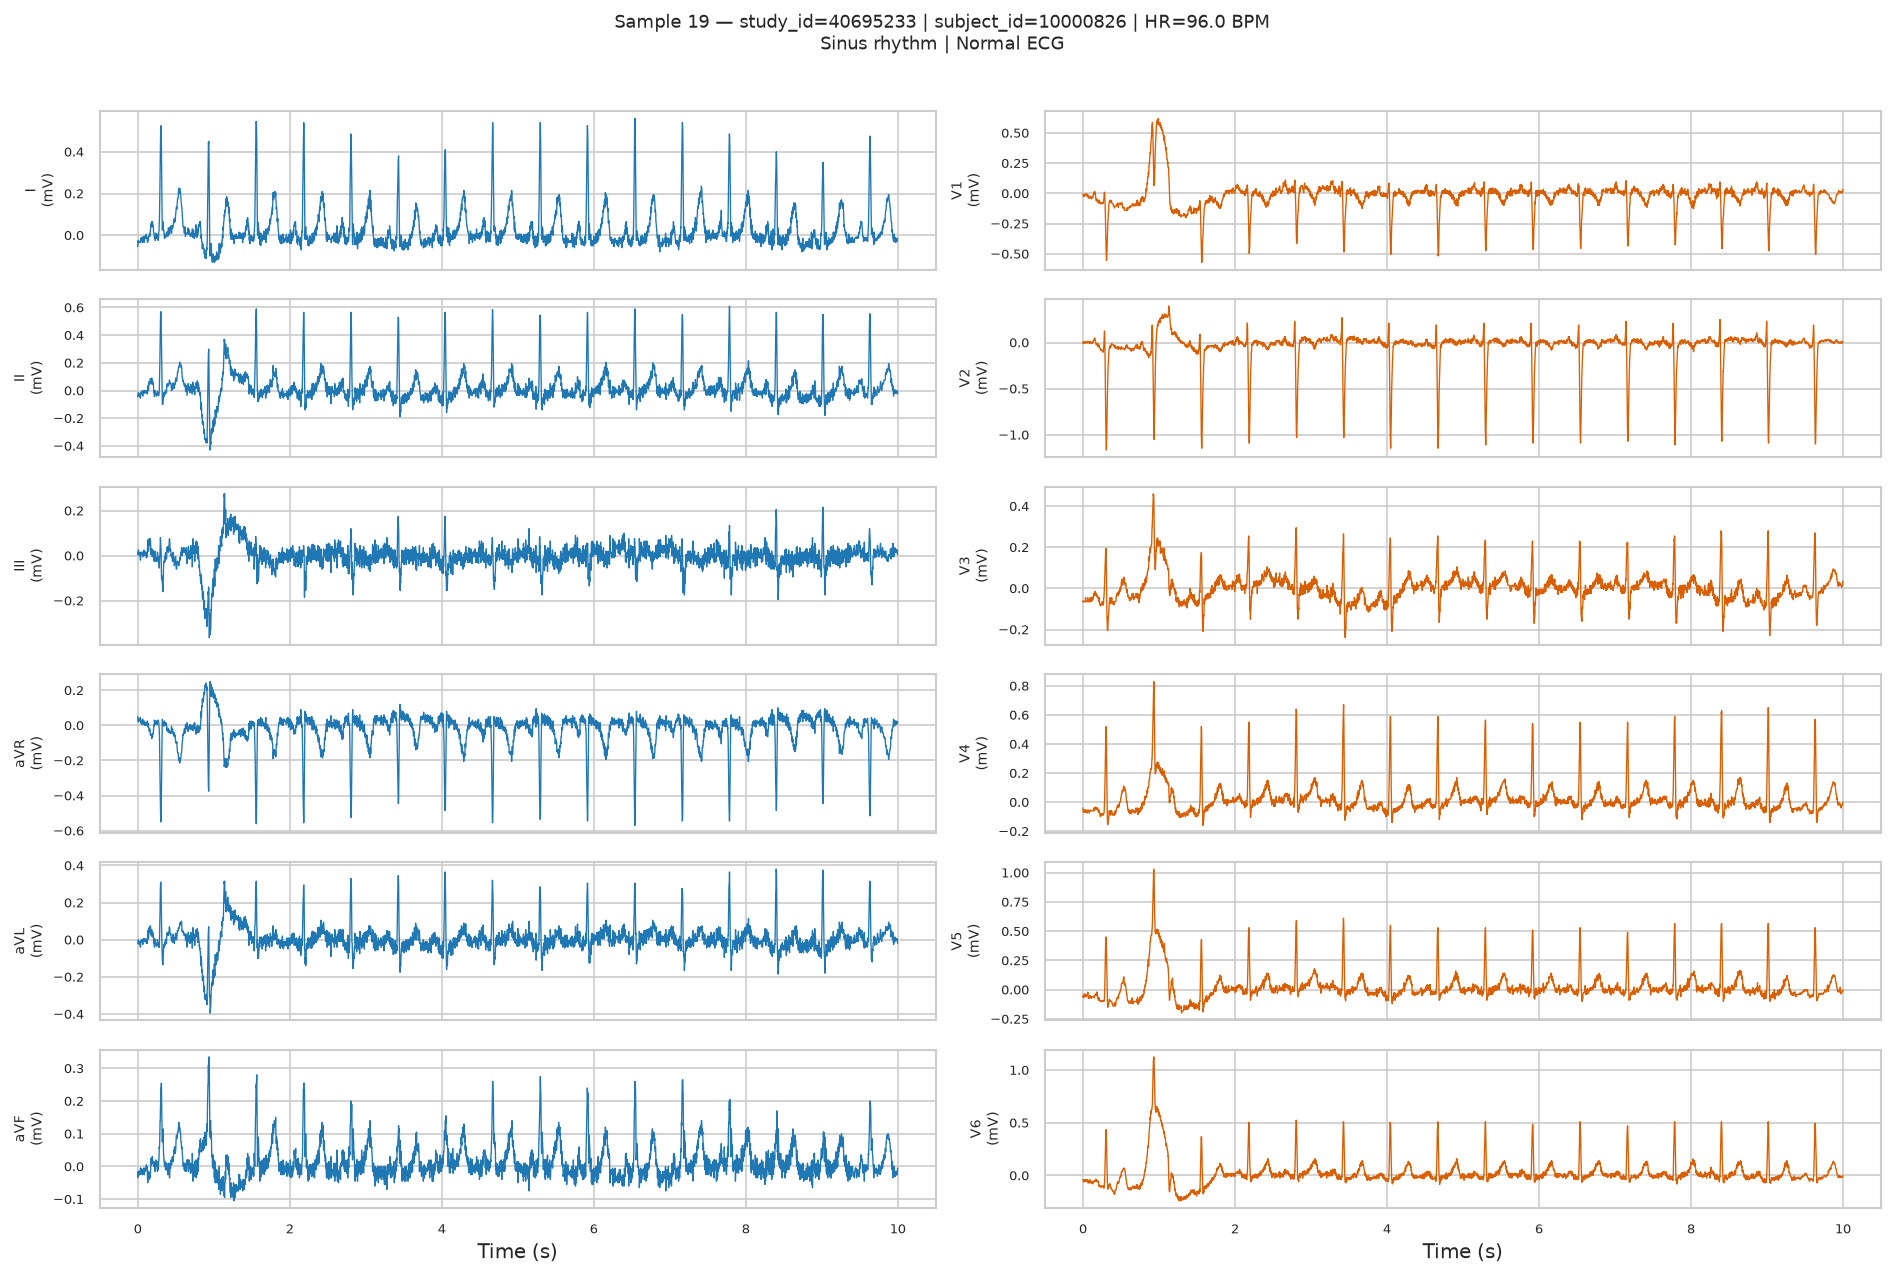

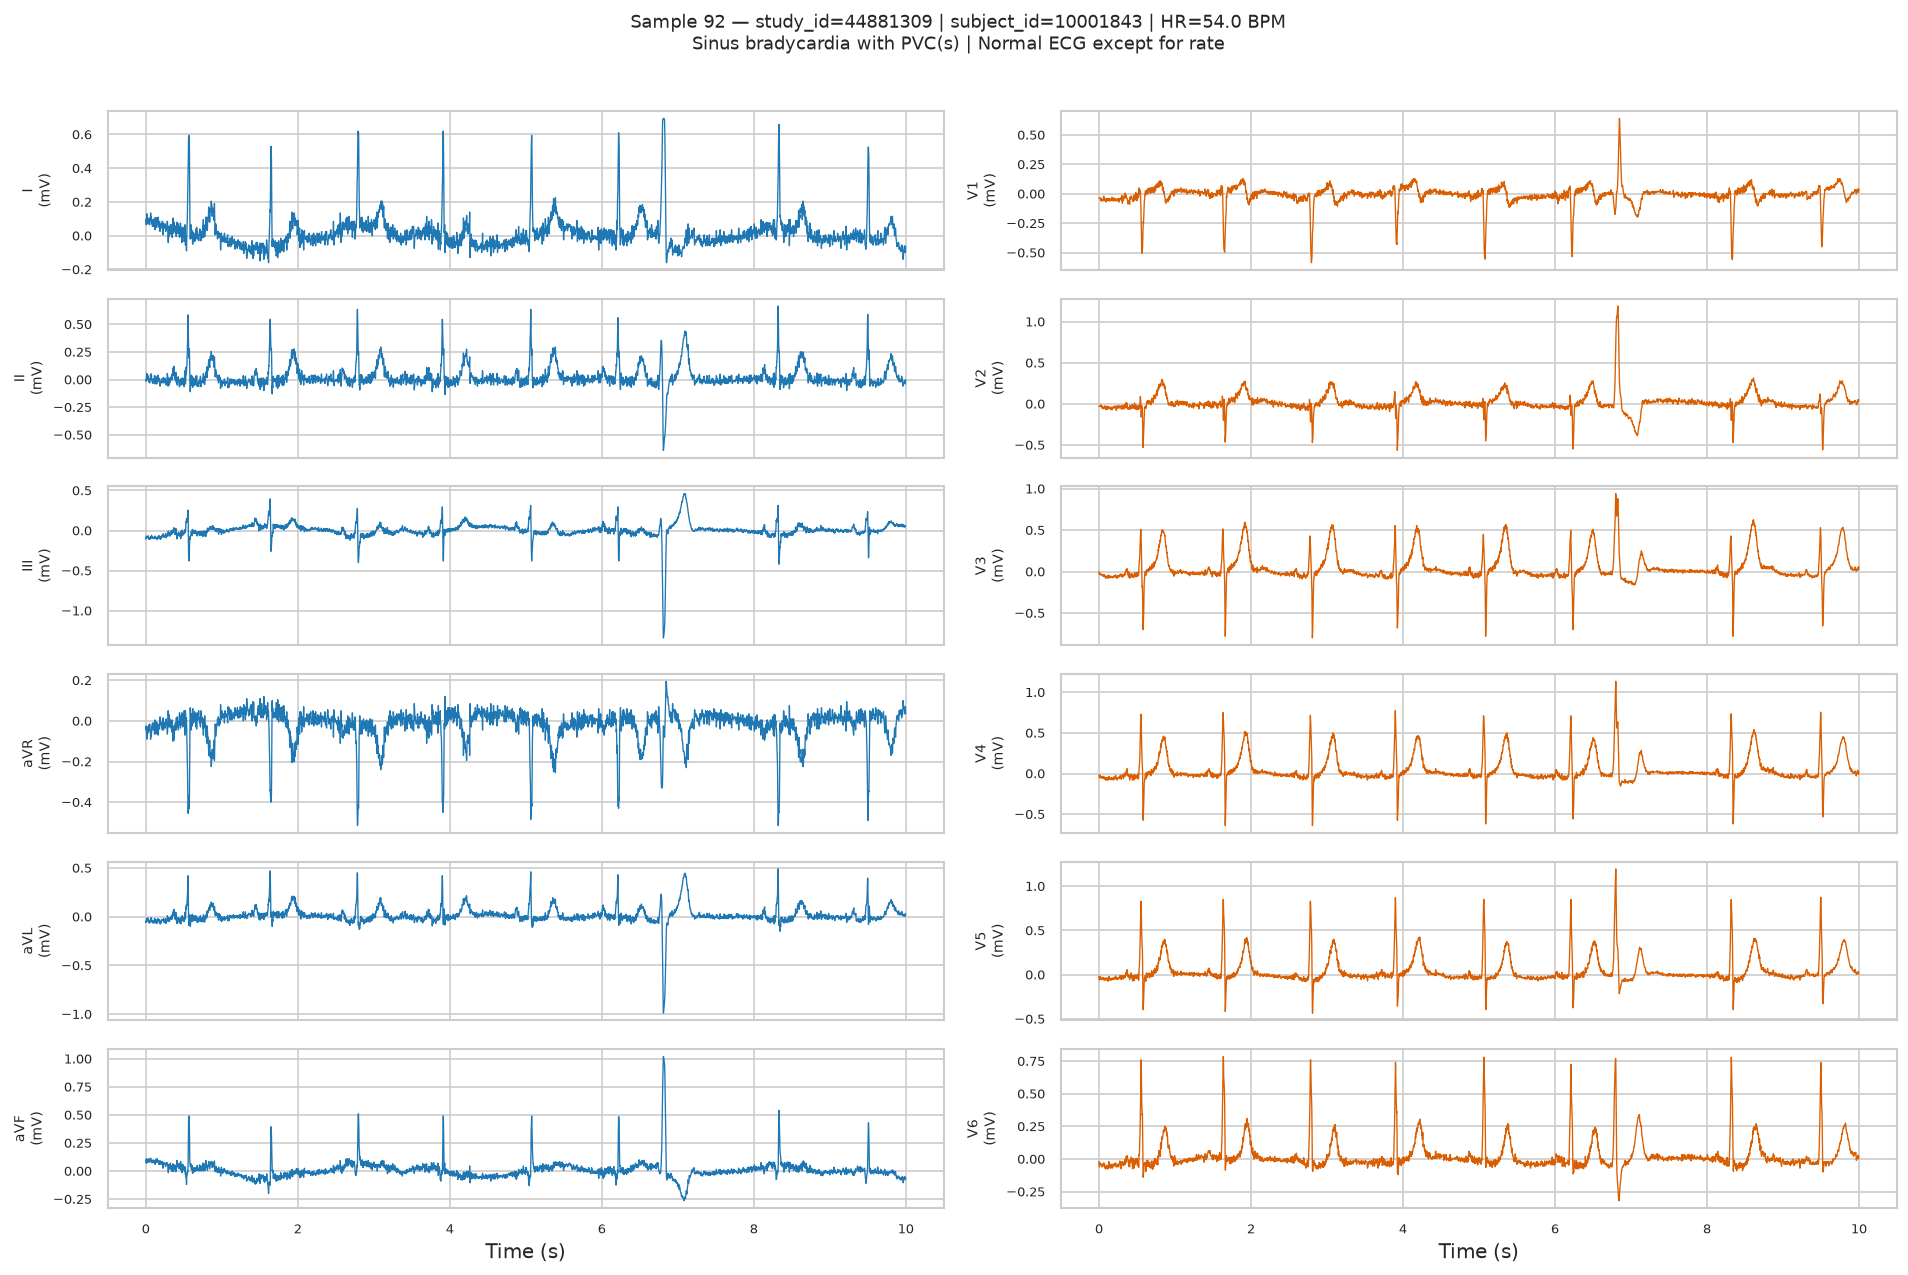

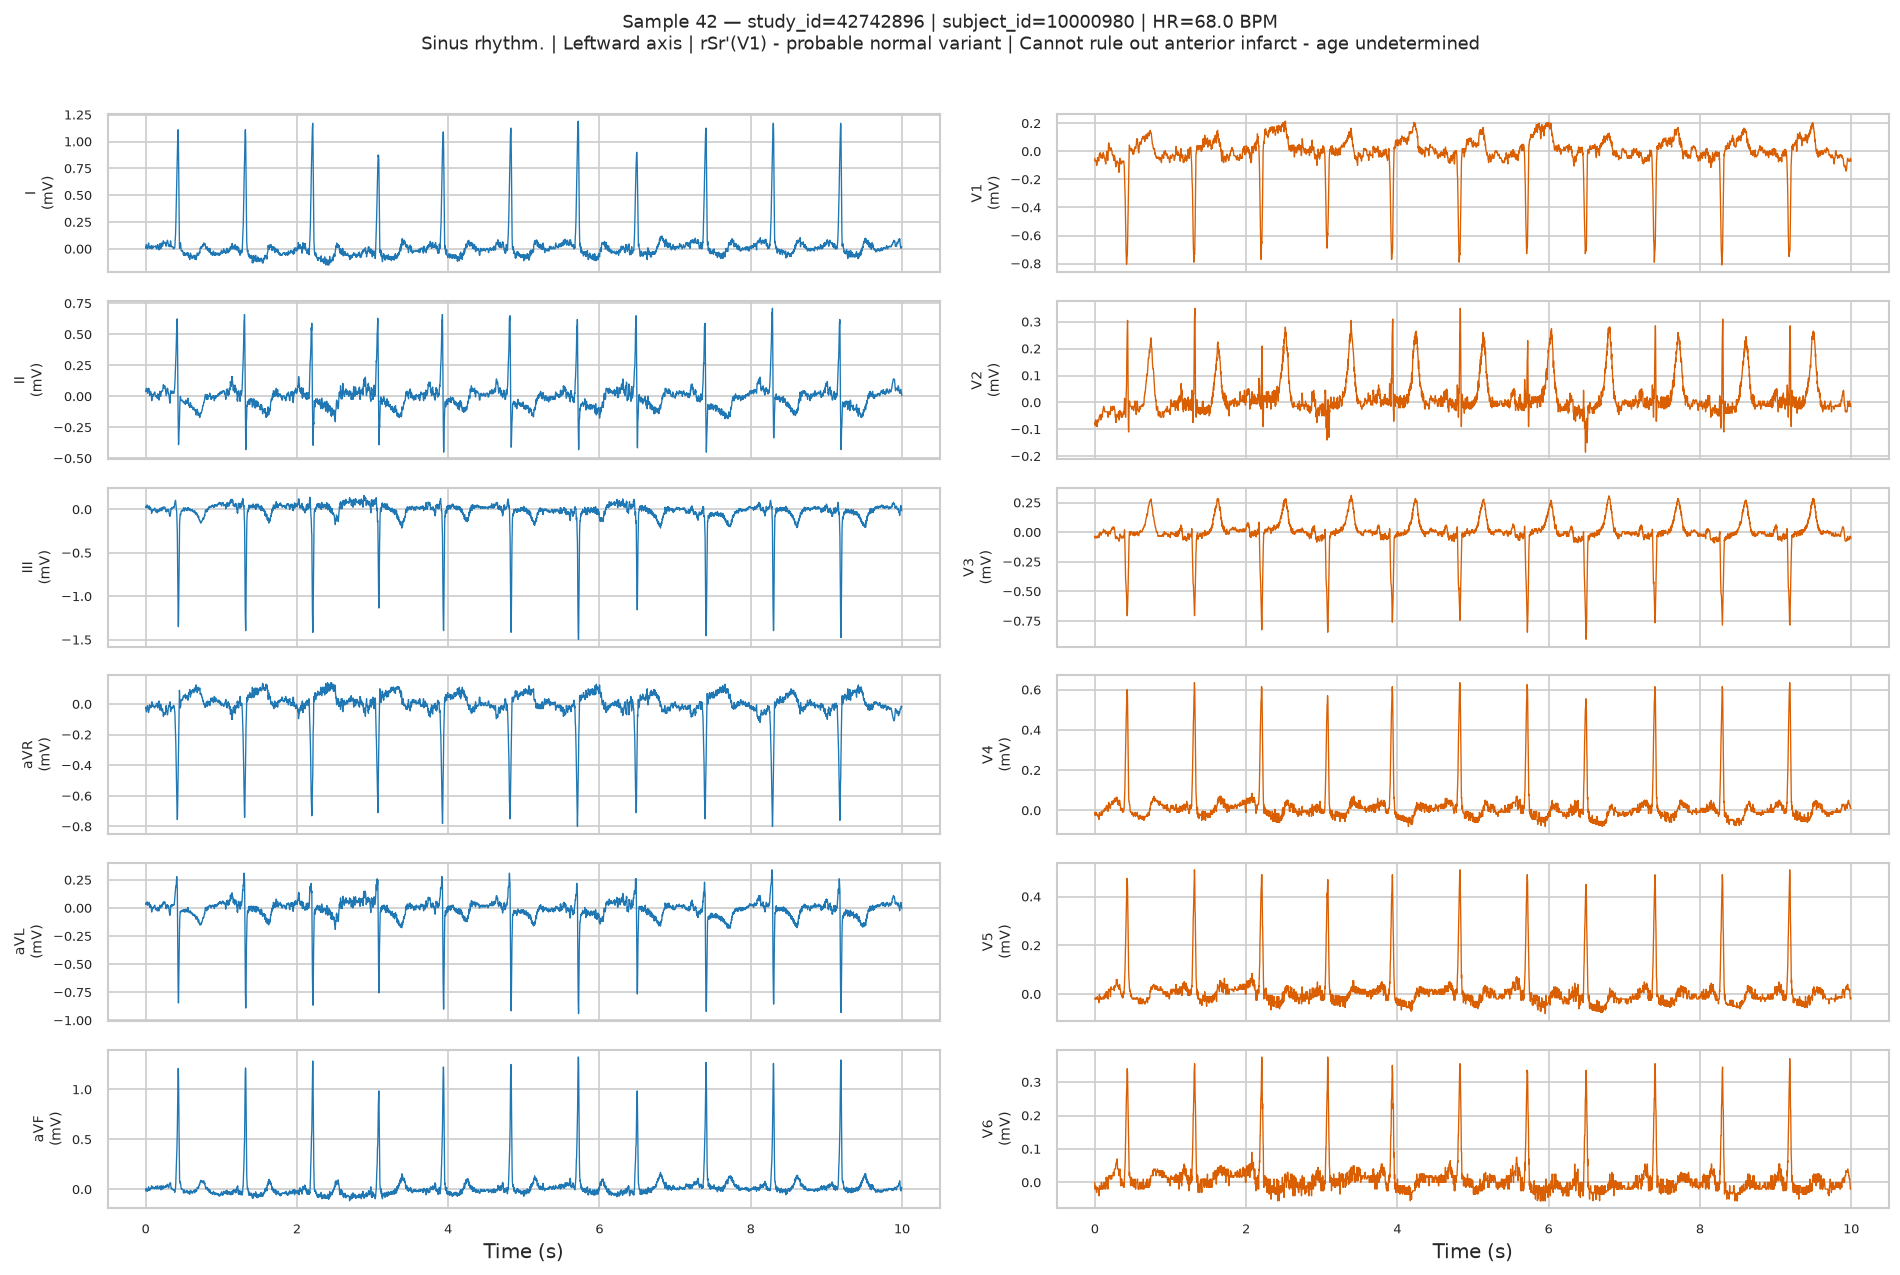

In [2]:
t_full = np.arange(5000) / 500.0

for idx in SAMPLE_INDICES:
    sig = signals[idx]
    row = meta_df.loc[idx]
    fig, axes = plt.subplots(6, 2, figsize=(16, 10.5), sharex=True)
    for j, lname in enumerate(LEADS):
        ax = axes[j % 6, j // 6]
        ax.plot(t_full, sig[:, j], color="#1f78b4" if j < 6 else "#d95f02", lw=0.8)
        ax.set_ylabel(f"{lname}\n(mV)", fontsize=8.5)
        ax.tick_params(labelsize=7.5)
    axes[5, 0].set_xlabel("Time (s)")
    axes[5, 1].set_xlabel("Time (s)")
    fig.suptitle(
        f"Sample {idx} — study_id={row["study_id"]} | subject_id={row["subject_id"]} | HR={row["hr_bpm"]} BPM\n"
        f"{row["report"][:120]}",
        y=1.01, fontsize=10.5,
    )
    plt.tight_layout()
    plt.show()

## 2. Side-by-Side Lineplot Comparison (`0–5 s` Zoom: Lead II & Lead V2)

Direct lineplot comparison of all five samples (`11`, `13`, `19`, `92`, `42`) in Lead II (limb rhythm lead) and Lead V2 (anterior precordial lead).

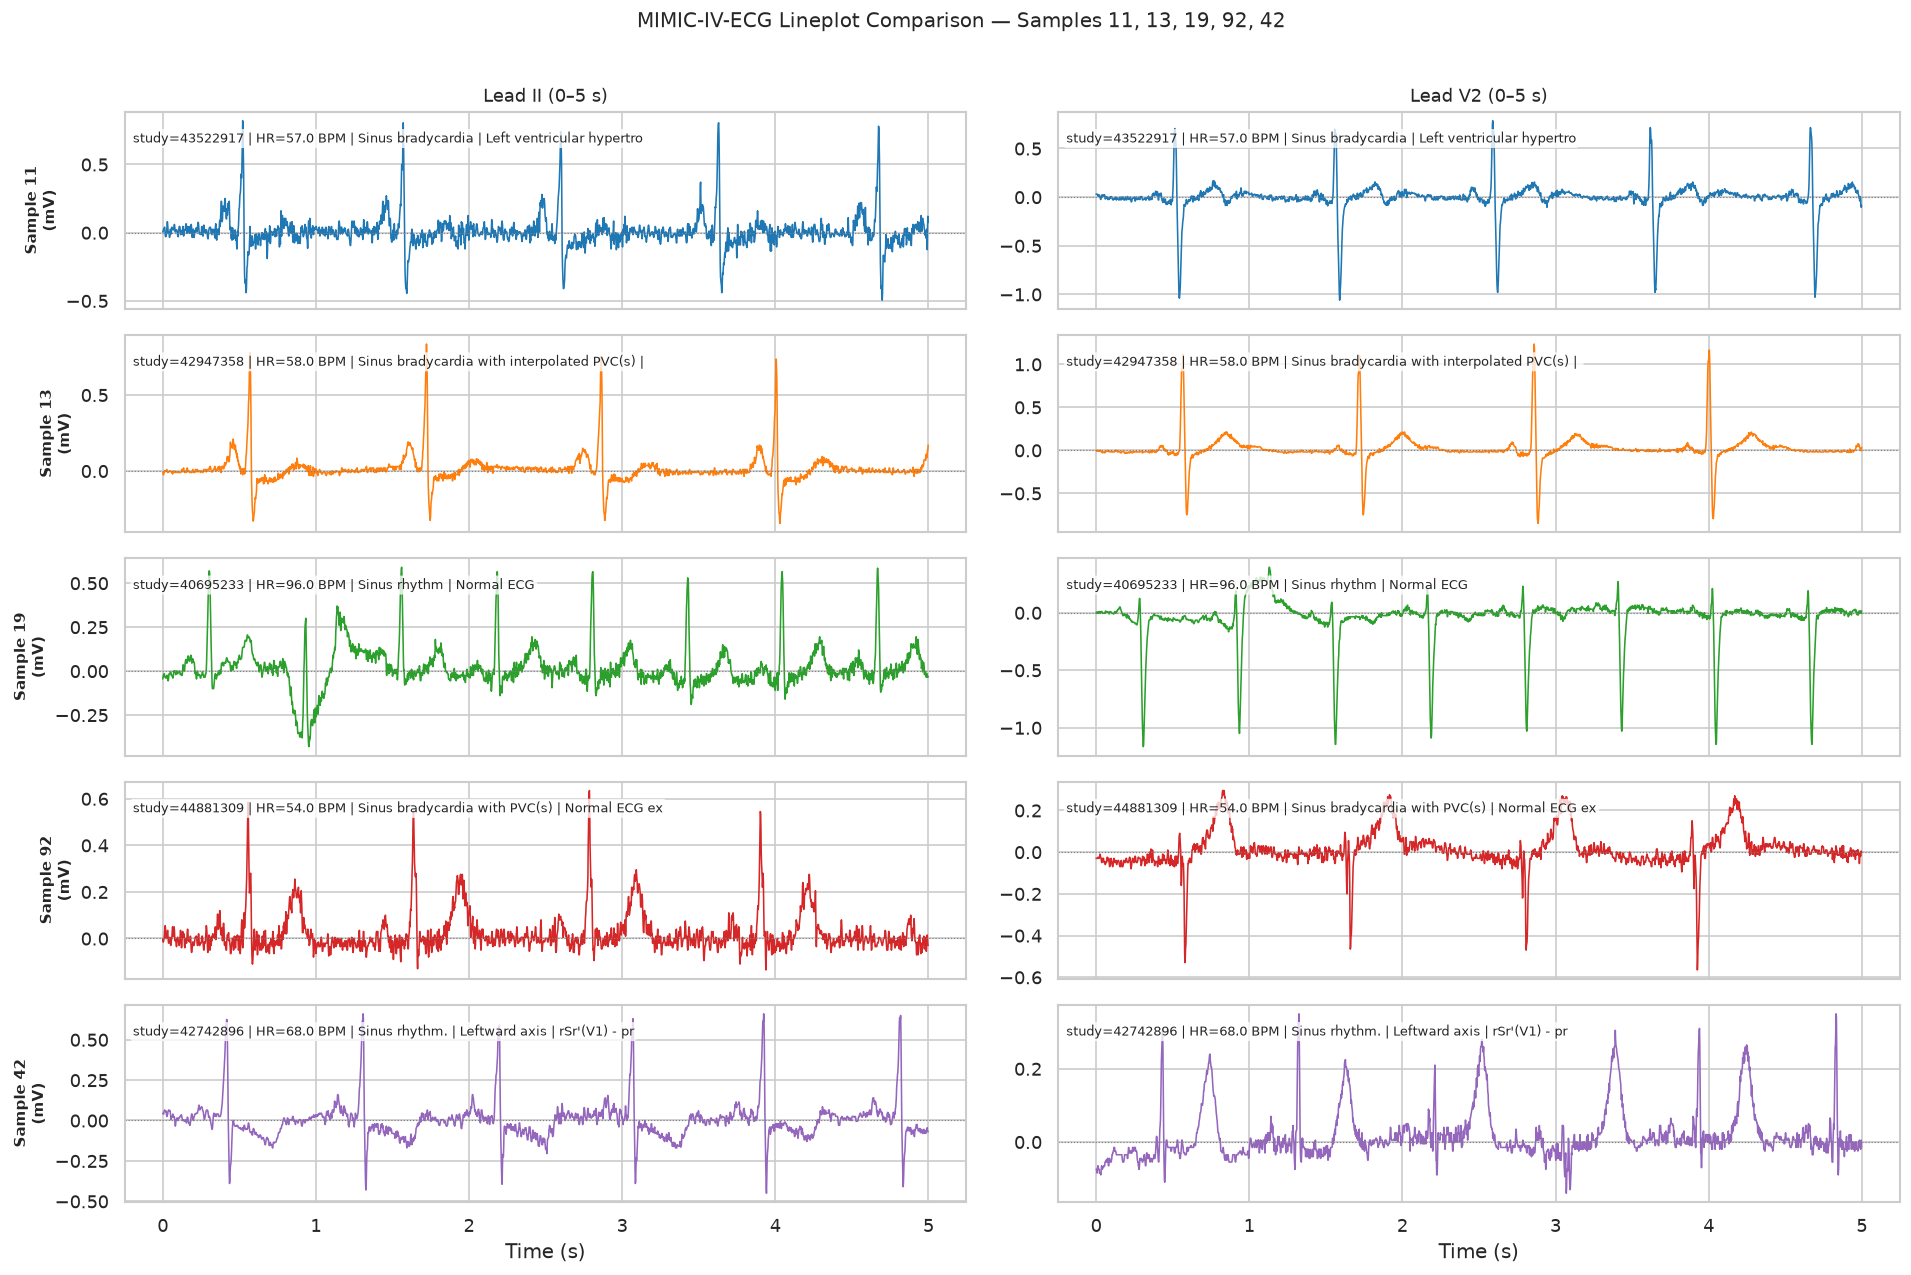

In [3]:
T_ZOOM = 2500  # 5.0 seconds @ 500 Hz
t_zoom = np.arange(T_ZOOM) / 500.0
colors = sns.color_palette("tab10", n_colors=len(SAMPLE_INDICES))

fig, axes = plt.subplots(len(SAMPLE_INDICES), 2, figsize=(16, 10.5), sharex=True)

for r_i, (idx, col) in enumerate(zip(SAMPLE_INDICES, colors)):
    sig = signals[idx]
    row = meta_df.loc[idx]
    for c_i, (l_idx, lname) in enumerate([(1, "II"), (7, "V2")]):
        ax = axes[r_i, c_i]
        ax.plot(t_zoom, sig[:T_ZOOM, l_idx], color=col, lw=0.95)
        ax.axhline(0, color="gray", ls=":", lw=0.7)
        if c_i == 0:
            ax.set_ylabel(f"Sample {idx}\n(mV)", fontsize=9, fontweight="bold")
        if r_i == 0:
            ax.set_title(f"Lead {lname} (0–5 s)", fontsize=10.5)
        ax.text(
            0.01, 0.90,
            f"study={row["study_id"]} | HR={row["hr_bpm"]} BPM | {row["report"][:45]}",
            transform=ax.transAxes, fontsize=7.5, va="top",
            bbox=dict(boxstyle="round,pad=0.2", facecolor="white", alpha=0.78, edgecolor="none"),
        )

axes[-1, 0].set_xlabel("Time (s)")
axes[-1, 1].set_xlabel("Time (s)")
fig.suptitle("MIMIC-IV-ECG Lineplot Comparison — Samples 11, 13, 19, 92, 42", y=1.01, fontsize=12)
plt.tight_layout()
plt.show()